# 02 · Evolução Mensal de Pedidos, Receita e Ticket Médio + Previsão
**Tech Challenge – Fase 1 · POSTECH Data Analytics** · Trilha: *Crescimento e Receita*

**Pergunta de negócio:** *a Olist está crescendo de forma sustentável? De onde vem esse crescimento e o que
esperar dos próximos meses?*

**Métricas**
* **Pedidos** – pedidos únicos válidos (sem cancelados/indisponíveis), pela data de compra.
* **Receita (GMV)** – soma do valor dos itens (`price`), sem frete.
* **Ticket médio** – receita ÷ pedidos.
* **Clientes** – `customer_unique_id` distintos.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from olist_utils import *

set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

In [2]:
items = analysis_base()
pedidos = orders_base(items)
m = monthly_kpis(items)
m[["pedidos", "receita", "ticket_medio", "clientes", "receita_mom", "receita_yoy"]]

,pedidos,receita,ticket_medio,clientes,receita_mom,receita_yoy
month,,,,,,
2017-01-01,787,"120,098.27",152.60,753,NaN,NaN
2017-02-01,1718,"244,959.35",142.58,1693,1.04,NaN
2017-03-01,2617,"368,341.32",140.75,2577,0.50,NaN
2017-04-01,2377,"353,842.98",148.86,2345,-0.04,NaN
2017-05-01,3640,"503,159.19",138.23,3569,0.42,NaN
2017-06-01,3205,"429,916.61",134.14,3142,-0.15,NaN
2017-07-01,3946,"492,287.30",124.76,3872,0.15,NaN
2017-08-01,4272,"568,245.79",133.02,4191,0.15,NaN
2017-09-01,4227,"621,415.91",147.01,4154,0.09,NaN


## 1. Visão geral: comparação de períodos equivalentes (jan–ago)

In [3]:
def periodo(df, ini, fim):
    p = df.loc[ini:fim]
    return pd.Series({"pedidos": p["pedidos"].sum(), "receita": p["receita"].sum(),
                      "ticket_medio": p["receita"].sum() / p["pedidos"].sum(),
                      "receita_media_mensal": p["receita"].mean()})

comp = pd.DataFrame({"jan-ago/2017": periodo(m, "2017-01", "2017-08"),
                     "jan-ago/2018": periodo(m, "2018-01", "2018-08")})
comp["variação"] = comp["jan-ago/2018"] / comp["jan-ago/2017"] - 1
comp

,jan-ago/2017,jan-ago/2018,variação
pedidos,"22,562.00","53,530.00",1.37
receita,"3,080,850.81","7,341,037.41",1.38
ticket_medio,136.55,137.14,0.00
receita_media_mensal,"385,106.35","917,629.68",1.38


In [4]:
total = pd.Series({
    "Receita total (jan/17–ago/18)": brl(m["receita"].sum()),
    "Pedidos": fmt_int(m["pedidos"].sum()),
    "Ticket médio": brl(m["receita"].sum() / m["pedidos"].sum(), 2),
    "Crescimento receita jan–ago 18 vs 17": pct(comp.loc["receita", "variação"]),
    "Crescimento pedidos jan–ago 18 vs 17": pct(comp.loc["pedidos", "variação"]),
    "Variação ticket médio": pct(comp.loc["ticket_medio", "variação"]),
})
total.to_frame("KPI")

,KPI
Receita total (jan/17–ago/18),R$ 13.449.530
Pedidos,97.905
Ticket médio,"R$ 137,37"
Crescimento receita jan–ago 18 vs 17,"138,3%"
Crescimento pedidos jan–ago 18 vs 17,"137,3%"
Variação ticket médio,"0,4%"


**Leitura:** a receita de jan–ago/2018 foi **2,4x** a do mesmo período de 2017 (+138%). O número de
pedidos cresceu na mesma proporção (+137%), enquanto o ticket médio ficou praticamente estável (+0,4%).
➡️ **O crescimento veio de volume (mais pedidos), não de preço.**

## 2. Receita mensal: forte expansão em 2017 e platô em 2018

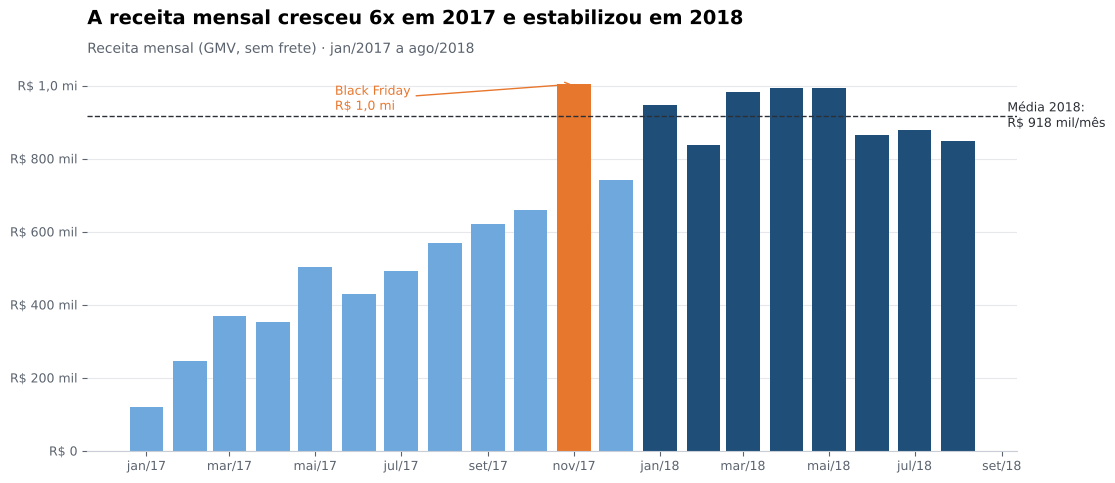

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
cores = [COLORS["accent"] if d == pd.Timestamp("2017-11-01") else
         (COLORS["primary"] if d.year == 2018 else COLORS["secondary"]) for d in m.index]
ax.bar(m.index, m["receita"], width=24, color=cores)
media18 = m.loc["2018", "receita"].mean()
ax.axhline(media18, color=COLORS["dark"], ls="--", lw=1)
ax.text(pd.Timestamp("2018-09-05"), media18, f"Média 2018:\n{brl_short(media18)}/mês",
        fontsize=9, color=COLORS["dark"], va="center")
bf = m.loc["2017-11-01", "receita"]
ax.annotate(f"Black Friday\n{brl_short(bf)}", xy=(pd.Timestamp("2017-11-01"), bf),
            xytext=(pd.Timestamp("2017-05-15"), bf * 0.93), fontsize=9, color=COLORS["accent"],
            arrowprops=dict(arrowstyle="->", color=COLORS["accent"]))
ax.set_title("A receita mensal cresceu 6x em 2017 e estabilizou em 2018")
subtitle(ax, "Receita mensal (GMV, sem frete) · jan/2017 a ago/2018")
axis_brl(ax)
month_axis(ax)
save(fig, "01_receita_mensal")
plt.show()

In [6]:
plato = m.loc["2018-01":"2018-08", "receita"]
print(f"Receita jan/2017: {brl(m.loc['2017-01-01','receita'])}  →  dez/2017: {brl(m.loc['2017-12-01','receita'])}"
      f"  ({m.loc['2017-12-01','receita']/m.loc['2017-01-01','receita']:.1f}x)")
print(f"2018: mínimo {brl(plato.min())} · máximo {brl(plato.max())} · coef. de variação {plato.std()/plato.mean():.1%}")
print(f"Ago/2018 vs jan/2018: {pct(plato.iloc[-1]/plato.iloc[0]-1)}")

Receita jan/2017: R$ 120.098  →  dez/2017: R$ 742.184  (6.2x)
2018: mínimo R$ 837.895 · máximo R$ 993.593 · coef. de variação 7.3%
Ago/2018 vs jan/2018: -10,2%


## 3. Pedidos e ticket médio: o motor do crescimento

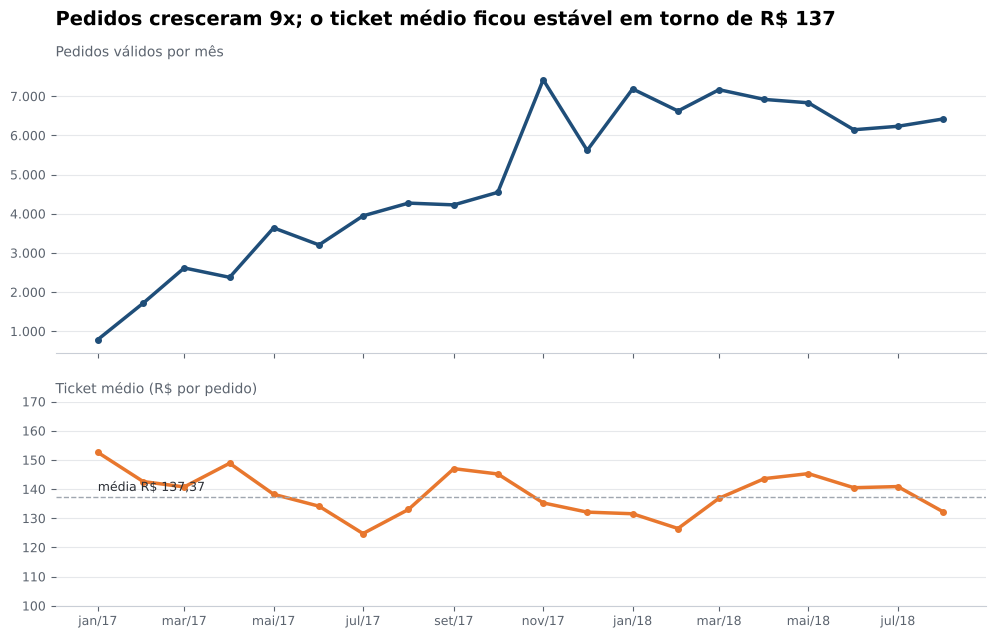

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                               gridspec_kw={"height_ratios": [1.4, 1]})
ax1.plot(m.index, m["pedidos"], color=COLORS["primary"], lw=2.5, marker="o", ms=4)
ax1.set_title("Pedidos cresceram 9x; o ticket médio ficou estável em torno de R$ 137")
subtitle(ax1, "Pedidos válidos por mês")
axis_int(ax1)
tm = m["receita"].sum() / m["pedidos"].sum()
ax2.plot(m.index, m["ticket_medio"], color=COLORS["accent"], lw=2.5, marker="o", ms=4)
ax2.axhline(tm, color=COLORS["neutral"], ls="--", lw=1)
ax2.set_ylim(100, 170)
ax2.text(m.index[0], tm + 2, f"média {brl(tm, 2)}", fontsize=9, color=COLORS["dark"])
subtitle(ax2, "Ticket médio (R$ por pedido)")
month_axis(ax2)
save(fig, "02_pedidos_ticket")
plt.show()

### Decomposição do crescimento
Receita = Pedidos × Ticket. Em log, a variação da receita se divide exatamente entre os dois fatores.

In [8]:
a17, a18 = comp["jan-ago/2017"], comp["jan-ago/2018"]
d_total = np.log(a18["receita"] / a17["receita"])
d_vol = np.log(a18["pedidos"] / a17["pedidos"])
d_tkt = np.log(a18["ticket_medio"] / a17["ticket_medio"])
pd.Series({"volume (pedidos)": d_vol / d_total, "preço (ticket médio)": d_tkt / d_total},
          name="contribuição para o crescimento").map(pct).to_frame()

,contribuição para o crescimento
volume (pedidos),"99,5%"
preço (ticket médio),"0,5%"


## 4. A desaceleração em números: crescimento ano contra ano

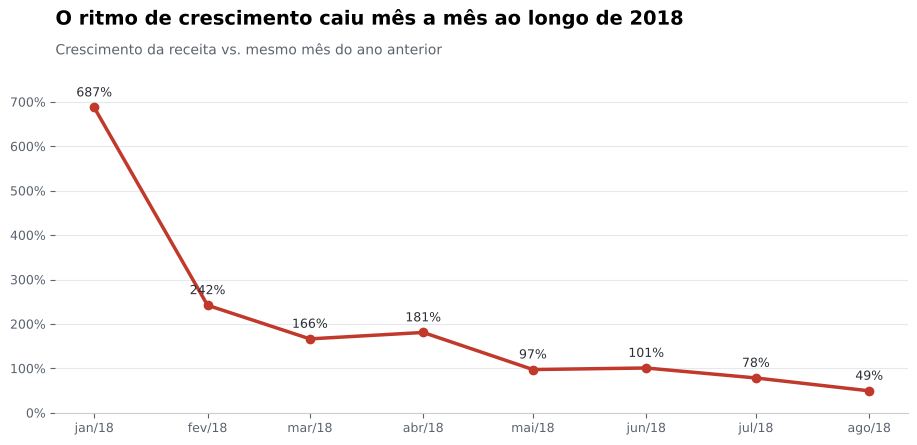

In [9]:
yoy = m.loc["2018", "receita_yoy"]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(yoy.index, yoy.values, color=COLORS["bad"], lw=2.5, marker="o")
for d, v in yoy.items():
    ax.text(d, v + 0.25, pct(v, 0), ha="center", fontsize=9, color=COLORS["dark"])
ax.set_title("O ritmo de crescimento caiu mês a mês ao longo de 2018")
subtitle(ax, "Crescimento da receita vs. mesmo mês do ano anterior")
axis_pct(ax)
ax.set_ylim(0, 7.8)
month_axis(ax, 1)
save(fig, "03_crescimento_yoy")
plt.show()

**Leitura:** o crescimento anual parece espetacular (de +687% em jan para +49% em ago/2018), mas a curva
mostra que ele vem da **base baixa de 2017** – a receita mensal de 2018 está parada em torno de
R$ 0,9 milhão. Em ago/2018 a receita foi **10% menor que em jan/2018**. A empresa saiu da fase de
"tração" e precisa de novas alavancas.

## 5. Base de clientes: crescimento depende de aquisição

In [10]:
primeira = pedidos.groupby("customer_unique_id")["purchase"].min().rename("primeira_compra")
pedidos = pedidos.join(primeira, on="customer_unique_id")
pedidos["tipo"] = np.where(pedidos["purchase"] == pedidos["primeira_compra"], "Novo", "Recorrente")
mix = pedidos.pivot_table(index="month", columns="tipo", values="revenue", aggfunc="sum").fillna(0)
mix_share = mix.div(mix.sum(axis=1), axis=0)

compras = pedidos.groupby("customer_unique_id")["order_id"].nunique()
print(f"Clientes únicos: {fmt_int(len(compras))}")
print(f"Clientes com 2+ pedidos: {fmt_int((compras > 1).sum())} ({pct((compras > 1).mean())})")
print(f"Receita de pedidos recorrentes no período: {pct(mix['Recorrente'].sum() / mix.values.sum())}")

Clientes únicos: 94.703
Clientes com 2+ pedidos: 2.874 (3,0%)
Receita de pedidos recorrentes no período: 2,7%


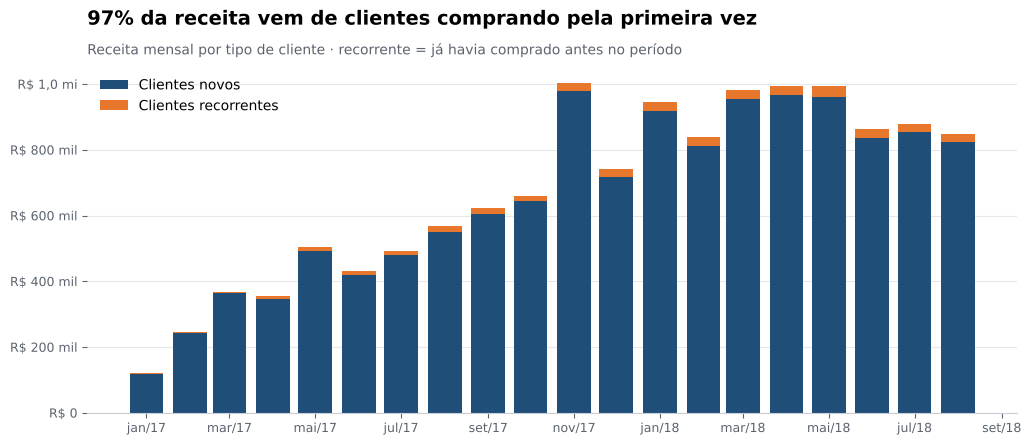

In [11]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(mix.index, mix["Novo"], width=24, color=COLORS["primary"], label="Clientes novos")
ax.bar(mix.index, mix["Recorrente"], width=24, bottom=mix["Novo"], color=COLORS["accent"],
       label="Clientes recorrentes")
ax.set_title("97% da receita vem de clientes comprando pela primeira vez")
subtitle(ax, "Receita mensal por tipo de cliente · recorrente = já havia comprado antes no período")
axis_brl(ax)
ax.legend(loc="upper left")
month_axis(ax)
save(fig, "04_novos_vs_recorrentes")
plt.show()

**Leitura:** apenas ~3% dos clientes voltaram a comprar no período. Toda nova receita precisa ser
"comprada" com aquisição de clientes – o que explica o platô quando o ritmo de aquisição estabiliza.
Retenção é a principal alavanca de crescimento barata e ainda inexplorada.

## 6. Sazonalidade: dias da semana e Black Friday

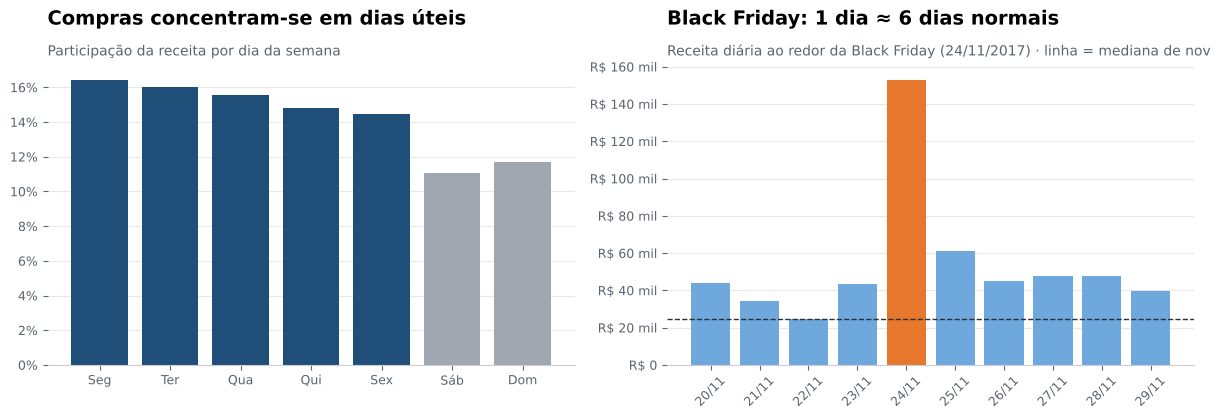

Receita em 24/11/2017: R$ 152.654 = 6.2x a mediana diária de novembro


In [12]:
dow_map = {0: "Seg", 1: "Ter", 2: "Qua", 3: "Qui", 4: "Sex", 5: "Sáb", 6: "Dom"}
dow = pedidos.groupby(pedidos["purchase"].dt.dayofweek)["revenue"].sum()
dow = dow / dow.sum()
bf = pedidos[(pedidos["purchase"] >= "2017-11-20") & (pedidos["purchase"] < "2017-11-30")]
bf_dia = bf.groupby(bf["purchase"].dt.date)["revenue"].sum()
media_nov = pedidos[pedidos["month"] == "2017-11-01"].groupby(pedidos["purchase"].dt.date)["revenue"].sum().median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
ax1.bar([dow_map[i] for i in dow.index], dow.values,
        color=[COLORS["primary"] if i < 5 else COLORS["neutral"] for i in dow.index])
ax1.set_title("Compras concentram-se em dias úteis")
subtitle(ax1, "Participação da receita por dia da semana")
axis_pct(ax1)
ax2.bar([d.strftime("%d/%m") for d in bf_dia.index], bf_dia.values,
        color=[COLORS["accent"] if d.day == 24 else COLORS["secondary"] for d in bf_dia.index])
ax2.axhline(media_nov, color=COLORS["dark"], ls="--", lw=1)
ax2.set_title("Black Friday: 1 dia ≈ 6 dias normais")
subtitle(ax2, "Receita diária ao redor da Black Friday (24/11/2017) · linha = mediana de nov")
axis_brl(ax2)
ax2.tick_params(axis="x", rotation=45)
fig.tight_layout()
save(fig, "05_sazonalidade")
plt.show()
print(f"Receita em 24/11/2017: {brl(bf_dia.loc[pd.Timestamp('2017-11-24').date()])} "
      f"= {bf_dia.loc[pd.Timestamp('2017-11-24').date()] / media_nov:.1f}x a mediana diária de novembro")

## 7. Previsão de receita (set/2018 – fev/2019)

Com apenas 20 meses de histórico (e uma única Black Friday), modelos complexos tendem a "decorar" o passado.
Comparamos três abordagens simples e transparentes:

| Modelo | Ideia |
|---|---|
| **Ingênuo** | o próximo mês repete o último |
| **Média móvel 3 meses (MM3)** | o próximo mês repete a média do último trimestre |
| **Holt amortecido** | projeta nível + tendência recente, "freando" a tendência no tempo (implementação própria em `src/olist_utils.py`) |

**Validação (backtest com origem móvel):** treinamos o modelo até fev, mar e abr/2018 e prevemos os 4 meses
seguintes em cada caso, medindo o erro percentual médio absoluto (MAPE) contra o que realmente aconteceu.

In [13]:
serie = m["receita"]
H = 4
linhas = []
for corte in ["2018-02", "2018-03", "2018-04"]:
    treino = serie.loc[:corte]
    teste = serie.loc[pd.Timestamp(corte) + pd.offsets.MonthBegin(1):].iloc[:H]
    prev = {
        "Ingênuo": np.repeat(treino.iloc[-1], H),
        "Média móvel 3m": np.repeat(treino.iloc[-3:].mean(), H),
        "Holt amortecido": holt_forecast(treino, horizon=H)[0]["previsao"].values,
    }
    for nome, p in prev.items():
        linhas.append({"corte": corte, "modelo": nome,
                       "MAPE": np.mean(np.abs(p - teste.values) / teste.values)})
bt = pd.DataFrame(linhas).pivot(index="modelo", columns="corte", values="MAPE")
bt["MAPE médio"] = bt.mean(axis=1)
bt.sort_values("MAPE médio").map(pct)

corte,2018-02,2018-03,2018-04,MAPE médio
modelo,,,,
Média móvel 3m,"11,8%","6,5%","7,8%","8,7%"
Ingênuo,"12,2%","7,0%","11,3%","10,2%"
Holt amortecido,"8,0%","9,1%","14,8%","10,6%"


**Escolha:** a **média móvel de 3 meses** teve o menor erro médio (~9%) e vira o **cenário base**.
O **Holt amortecido**, que ainda carrega parte da tendência de alta de 2017, é usado como **cenário otimista**.
Em ambos aplicamos o efeito Black Friday observado em 2017 (receita de nov ÷ média de set–out).

In [14]:
mape_base = bt.loc["Média móvel 3m", "MAPE médio"]
idx = pd.date_range("2018-09-01", periods=6, freq="MS")
efeito_bf = m.loc["2017-11-01", "receita"] / m.loc["2017-09":"2017-10", "receita"].mean()
holt, _, par = holt_forecast(serie, horizon=6)

fc = pd.DataFrame(index=idx)
fc["base"] = serie.iloc[-3:].mean()
fc["otimista"] = holt["previsao"].values
for c in ["base", "otimista"]:
    fc.loc["2018-11-01", c] *= efeito_bf
fc["faixa_inf"] = fc["base"] * (1 - mape_base)
fc["faixa_sup"] = fc["base"] * (1 + mape_base)
print(f"Efeito Black Friday 2017: {efeito_bf:.2f}x | parâmetros Holt: "
      f"alpha={par['alpha']:.2f}, beta={par['beta']:.2f}, phi={par['phi']:.2f}")
fc

Efeito Black Friday 2017: 1.57x | parâmetros Holt: alpha=0.36, beta=0.01, phi=0.89


,base,otimista,faixa_inf,faixa_sup
2018-09-01,"863,389.97","919,031.39","788,069.40","938,710.54"
2018-10-01,"863,389.97","927,509.76","788,069.40","938,710.54"
2018-11-01,"1,352,571.04","1,464,800.02","1,234,575.20","1,470,566.88"
2018-12-01,"863,389.97","941,698.63","788,069.40","938,710.54"
2019-01-01,"863,389.97","947,613.71","788,069.40","938,710.54"
2019-02-01,"863,389.97","952,859.90","788,069.40","938,710.54"


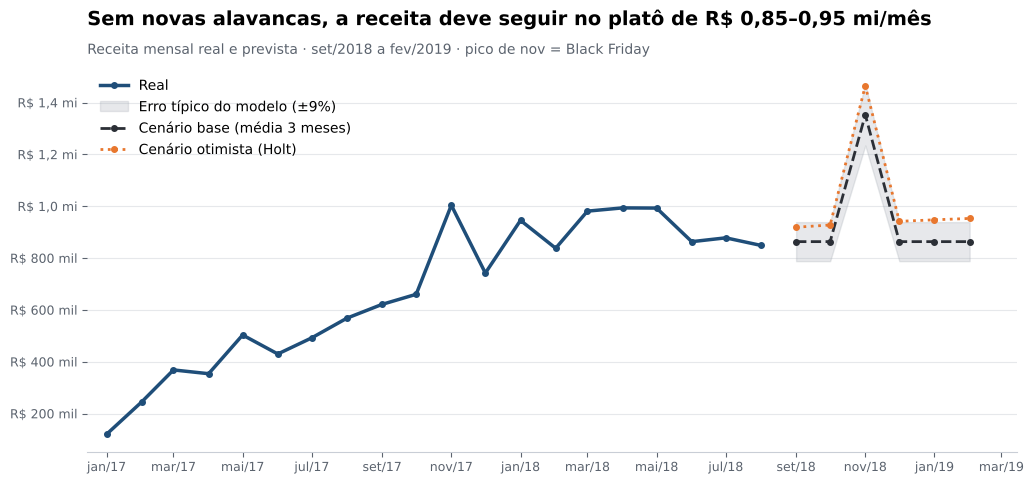

Cenário base: receita set/18–fev/19 = R$ 5.669.521 (2,0% vs últimos 6 meses, mar–ago/18)
Cenário otimista: receita set/18–fev/19 = R$ 6.153.513 (10,7% vs últimos 6 meses, mar–ago/18)
Receita mensal fora de novembro: base R$ 863.390 | otimista R$ 919.031–R$ 952.860


In [15]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(serie.index, serie.values, color=COLORS["primary"], lw=2.5, marker="o", ms=4, label="Real")
ax.fill_between(fc.index, fc["faixa_inf"], fc["faixa_sup"], color=COLORS["neutral"], alpha=0.25,
                label=f"Erro típico do modelo (±{mape_base:.0%})")
ax.plot(fc.index, fc["base"], color=COLORS["dark"], lw=2, ls="--", marker="o", ms=4,
        label="Cenário base (média 3 meses)")
ax.plot(fc.index, fc["otimista"], color=COLORS["accent"], lw=2, ls=":", marker="o", ms=4,
        label="Cenário otimista (Holt)")
ax.set_title("Sem novas alavancas, a receita deve seguir no platô de R$ 0,85–0,95 mi/mês")
subtitle(ax, "Receita mensal real e prevista · set/2018 a fev/2019 · pico de nov = Black Friday")
axis_brl(ax)
ax.legend(loc="upper left")
ax.set_xlim(pd.Timestamp("2016-12-15"), pd.Timestamp("2019-03-15"))
month_axis(ax)
save(fig, "06_previsao_receita")
plt.show()

ant = m.loc["2018-03":"2018-08", "receita"].sum()
for c in ["base", "otimista"]:
    print(f"Cenário {c}: receita set/18–fev/19 = {brl(fc[c].sum())} "
          f"({pct(fc[c].sum()/ant - 1)} vs últimos 6 meses, mar–ago/18)")
sem_nov = fc.drop(pd.Timestamp("2018-11-01"))
print(f"Receita mensal fora de novembro: base {brl(sem_nov['base'].iloc[0])} | otimista "
      f"{brl(sem_nov['otimista'].min())}–{brl(sem_nov['otimista'].max())}")

**Leitura da previsão:** mantidas as condições atuais, a receita mensal tende a ficar entre
R$ 0,86 mi (base) e R$ 0,95 mi (otimista). Mesmo com a Black Friday, o semestre set/18–fev/19 fica
apenas ~2% (base) a ~11% (otimista) acima dos últimos 6 meses – crescimento muito inferior ao histórico.
**O crescimento futuro depende de ações, não da inércia.**

> Limitações: série curta (20 meses, só uma Black Friday observada); a faixa de erro usa o MAPE do backtest
> e é aproximada. Recomenda-se reavaliar os modelos a cada novo mês de dados.

## Conclusões do notebook
1. **Crescimento forte, mas concentrado no passado:** receita jan–ago/18 +138% vs 2017; porém platô de
   ~R$ 0,9 mi/mês desde jan/2018 e queda de 10% de jan para ago/2018.
2. **Crescimento 100% via volume:** ticket médio estável (~R$ 137).
3. **Baixíssima recompra (~3%)**: a receita depende de captar clientes novos todo mês.
4. **Sazonalidade explorável:** Black Friday vale ~6 dias normais; dias úteis concentram as compras.
5. **Previsão:** platô de R$ 0,86–0,95 mi/mês se nada mudar (Black Friday ≈ R$ 1,35–1,46 mi).

➡️ Próximo: `03_categorias_e_regioes.ipynb`